In [1]:
import os
import sys
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.linear_model import (
    LogisticRegression,
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBClassifier

from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "lending_club_loans.csv"

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Figures directory:", FIGURES_DIR)
print("Models directory:", MODELS_DIR)

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

Project root: c:\Users\Admin\Desktop\python_new\github\week-2-weekly-assessment
Dataset path: c:\Users\Admin\Desktop\python_new\github\week-2-weekly-assessment\data\raw\lending_club_loans.csv
Figures directory: c:\Users\Admin\Desktop\python_new\github\week-2-weekly-assessment\reports\figures
Models directory: c:\Users\Admin\Desktop\python_new\github\week-2-weekly-assessment\models


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (396030, 27)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [4]:
df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

df["default"] = (
    df["loan_status"] == "Charged Off"
).astype(int)

print("Target distribution:")
display(df["default"].value_counts())

print("\nTarget percentages:")
display(
    df["default"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:


default
0    318357
1     77673
Name: count, dtype: int64


Target percentages:


default
0    80.39
1    19.61
Name: proportion, dtype: float64

In [7]:
classification_features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "issue_d",
    "purpose",
    "dti",
    "earliest_cr_line",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "initial_list_status",
    "application_type",
    "mort_acc",
    "pub_rec_bankruptcies"
]

X_cls = df[classification_features].copy()
y_cls = df["default"].copy()

print("Classification feature shape:", X_cls.shape)
print("Classification target shape:", y_cls.shape)

Classification feature shape: (396030, 23)
Classification target shape: (396030,)


In [8]:
all_indices = df.index

train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_cls.loc[train_val_indices]
)

X_train = X_cls.loc[train_indices]
X_val = X_cls.loc[val_indices]
X_test = X_cls.loc[test_indices]

y_train = y_cls.loc[train_indices]
y_val = y_cls.loc[val_indices]
y_test = y_cls.loc[test_indices]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 237618
Validation records: 79206
Testing records: 79206


In [9]:
split_distribution = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
}).T

display(
    split_distribution.mul(100).round(2)
)

default,0,1
Train,80.39,19.61
Validation,80.39,19.61
Test,80.39,19.61


In [10]:
sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import LoanFeatureEngineer

print("LoanFeatureEngineer imported successfully!")

LoanFeatureEngineer imported successfully!


In [11]:
numeric_features = [
    "loan_amnt",
    "int_rate",
    "installment",
    "annual_inc",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "mort_acc",
    "pub_rec_bankruptcies",
    "issue_year",
    "issue_month",
    "credit_history_months",
    "income_to_loan_ratio",
    "log_annual_inc"
]

ordinal_features = [
    "grade",
    "sub_grade"
]

categorical_features = [
    "term",
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose",
    "initial_list_status",
    "application_type"
]

grade_order = [
    "A", "B", "C", "D", "E", "F", "G"
]

sub_grade_order = [
    f"{grade}{number}"
    for grade in "ABCDEFG"
    for number in range(1, 6)
]

print("Numeric features:", len(numeric_features))
print("Ordinal features:", len(ordinal_features))
print("Categorical features:", len(categorical_features))

Numeric features: 17
Ordinal features: 2
Categorical features: 7


In [12]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(
        categories=[
            grade_order,
            sub_grade_order
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

classification_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
        ("ordinal", ordinal_transformer, ordinal_features)
    ],
    remainder="drop"
)

print("Classification preprocessor created successfully!")

Classification preprocessor created successfully!


In [13]:
def create_classification_pipeline(model):

    pipeline = Pipeline(steps=[
        ("feature_engineering", LoanFeatureEngineer()),
        ("preprocessor", classification_preprocessor),
        ("classifier", model)
    ])

    return pipeline

In [14]:
logistic_model = create_classification_pipeline(
    LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    )
)

random_forest_model = create_classification_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

xgboost_model = create_classification_pipeline(
    XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

print("Three classification models initialized!")

Three classification models initialized!


In [15]:
classification_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model
}

for model_name, model in classification_models.items():

    print(f"\nTraining {model_name}...")

    model.fit(
        X_train,
        y_train
    )

    print(f"{model_name} training completed!")


Training Logistic Regression...
Logistic Regression training completed!

Training Random Forest...
Random Forest training completed!

Training XGBoost...
XGBoost training completed!


In [16]:
validation_predictions = {}
validation_probabilities = {}

for model_name, model in classification_models.items():

    validation_predictions[model_name] = model.predict(X_val)

    validation_probabilities[model_name] = (
        model.predict_proba(X_val)[:, 1]
    )

print("Validation predictions generated!")

Validation predictions generated!


In [17]:
classification_results = []

for model_name in classification_models:

    y_pred = validation_predictions[model_name]
    y_prob = validation_probabilities[model_name]

    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_val, y_prob)
    })

classification_results_df = pd.DataFrame(
    classification_results
).sort_values(
    by="ROC AUC",
    ascending=False
)

display(
    classification_results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,XGBoost,0.6722,0.3323,0.6651,0.4432,0.7338
1,Random Forest,0.7251,0.3647,0.5414,0.4358,0.7232
0,Logistic Regression,0.8058,0.5314,0.0845,0.1458,0.7140


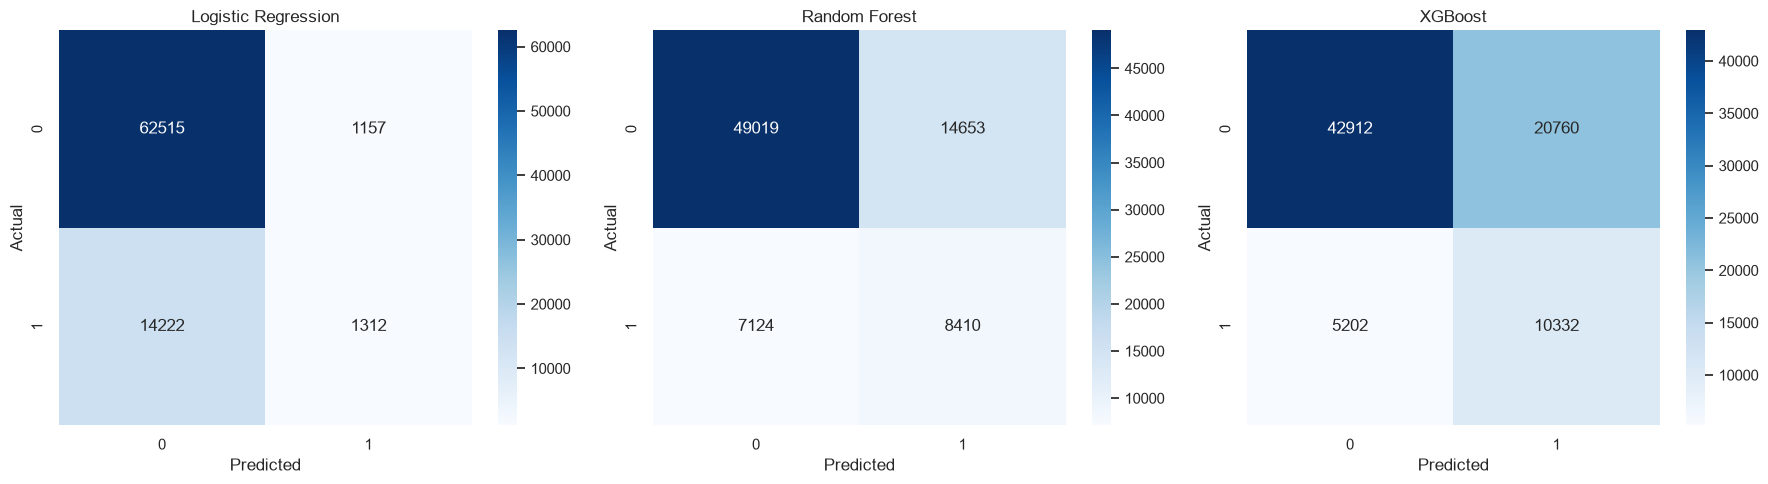

In [18]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (model_name, predictions) in zip(
    axes,
    validation_predictions.items()
):

    cm = confusion_matrix(
        y_val,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task4_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
for model_name, predictions in validation_predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_val,
            predictions,
            target_names=[
                "Fully Paid",
                "Charged Off"
            ],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

  Fully Paid       0.81      0.98      0.89     63672
 Charged Off       0.53      0.08      0.15     15534

    accuracy                           0.81     79206
   macro avg       0.67      0.53      0.52     79206
weighted avg       0.76      0.81      0.74     79206


Random Forest
              precision    recall  f1-score   support

  Fully Paid       0.87      0.77      0.82     63672
 Charged Off       0.36      0.54      0.44     15534

    accuracy                           0.73     79206
   macro avg       0.62      0.66      0.63     79206
weighted avg       0.77      0.73      0.74     79206


XGBoost
              precision    recall  f1-score   support

  Fully Paid       0.89      0.67      0.77     63672
 Charged Off       0.33      0.67      0.44     15534

    accuracy                           0.67     79206
   macro avg       0.61      0.67      0.61     79206
weighted avg       0.78      

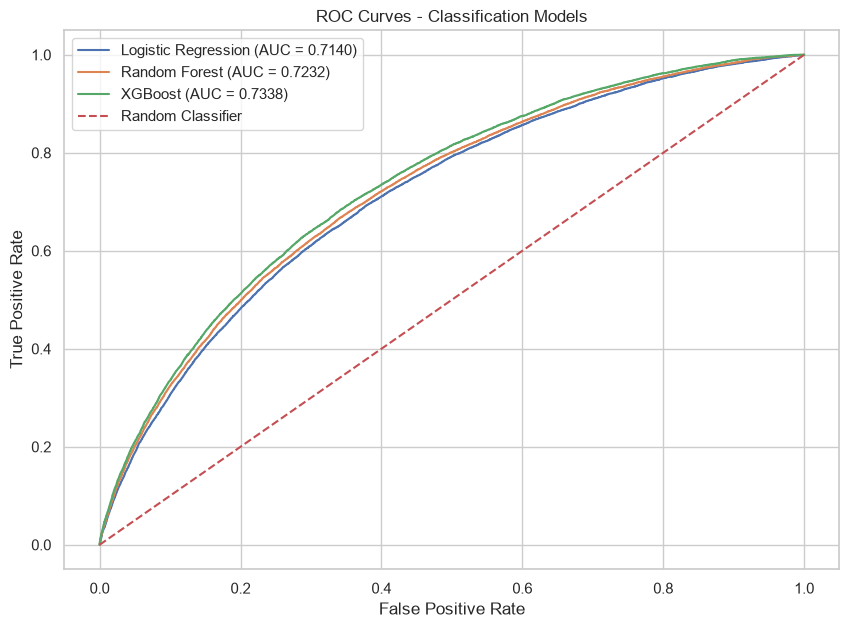

In [20]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in validation_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_val,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Classification Models")

plt.legend()
plt.grid(True)

plt.savefig(
    FIGURES_DIR / "task4_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
best_model_name = classification_results_df.iloc[0]["Model"]

best_classifier = classification_models[
    best_model_name
]

best_validation_probabilities = validation_probabilities[
    best_model_name
]

print("Best validation model:", best_model_name)

Best validation model: XGBoost


In [22]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val,
        best_validation_probabilities
    )
)

target_recall = 0.75

eligible_indices = np.where(
    recall_values[:-1] >= target_recall
)[0]

if len(eligible_indices) > 0:

    best_threshold_index = eligible_indices[
        np.argmax(precision_values[eligible_indices])
    ]

    selected_threshold = thresholds[
        best_threshold_index
    ]

    selected_precision = precision_values[
        best_threshold_index
    ]

    selected_recall = recall_values[
        best_threshold_index
    ]

else:

    raise ValueError(
        "No threshold achieved the required recall."
    )

print("Selected model:", best_model_name)
print("Selected threshold:", selected_threshold)
print("Precision:", selected_precision)
print("Recall:", selected_recall)

Selected model: XGBoost
Selected threshold: 0.44527903
Precision: 0.30494857770915657
Recall: 0.7501609372988284


              precision    recall  f1-score   support

  Fully Paid       0.91      0.58      0.71     63672
 Charged Off       0.30      0.75      0.43     15534

    accuracy                           0.62     79206
   macro avg       0.61      0.67      0.57     79206
weighted avg       0.79      0.62      0.66     79206



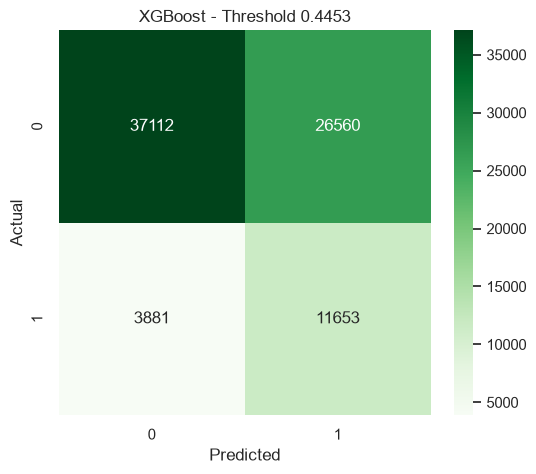

In [23]:
threshold_predictions = (
    best_validation_probabilities >= selected_threshold
).astype(int)

print(
    classification_report(
        y_val,
        threshold_predictions,
        target_names=[
            "Fully Paid",
            "Charged Off"
        ],
        zero_division=0
    )
)

threshold_cm = confusion_matrix(
    y_val,
    threshold_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    threshold_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title(
    f"{best_model_name} - Threshold {selected_threshold:.4f}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    FIGURES_DIR / "task4_threshold_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
rf_pipeline = create_classification_pipeline(
    RandomForestClassifier(
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
)

rf_parameter_grid = {
    "classifier__n_estimators": [100, 150],
    "classifier__max_depth": [10, 15],
    "classifier__min_samples_leaf": [5, 10]
}

rf_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Optimized Random Forest parameter grid:")
display(rf_parameter_grid)

Optimized Random Forest parameter grid:


{'classifier__n_estimators': [100, 150],
 'classifier__max_depth': [10, 15],
 'classifier__min_samples_leaf': [5, 10]}

In [27]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_parameter_grid,
    scoring="roc_auc",
    cv=rf_cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

rf_grid_search.fit(
    X_train,
    y_train
)

print("Random Forest tuning completed!")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Random Forest tuning completed!


In [28]:
print("Best Random Forest parameters:")
display(rf_grid_search.best_params_)

print(
    "Best cross-validation ROC-AUC:",
    round(rf_grid_search.best_score_, 4)
)

best_rf_model = rf_grid_search.best_estimator_

Best Random Forest parameters:


{'classifier__max_depth': 15,
 'classifier__min_samples_leaf': 10,
 'classifier__n_estimators': 150}

Best cross-validation ROC-AUC: 0.7229


In [29]:
rf_results_df = pd.DataFrame(
    rf_grid_search.cv_results_
).sort_values(
    by="rank_test_score"
)

display(
    rf_results_df[
        [
            "params",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].head(10)
)

,params,mean_test_score,std_test_score,rank_test_score
7,"{'classifier__max_depth': 15, 'classifier__min...",0.722870,0.001092,1
6,"{'classifier__max_depth': 15, 'classifier__min...",0.722240,0.001203,2
5,"{'classifier__max_depth': 15, 'classifier__min...",0.721972,0.000959,3
4,"{'classifier__max_depth': 15, 'classifier__min...",0.721450,0.000943,4
3,"{'classifier__max_depth': 10, 'classifier__min...",0.720182,0.001064,5
1,"{'classifier__max_depth': 10, 'classifier__min...",0.719945,0.001142,6
2,"{'classifier__max_depth': 10, 'classifier__min...",0.719895,0.001080,7
0,"{'classifier__max_depth': 10, 'classifier__min...",0.719810,0.001271,8


In [30]:
xgb_pipeline = create_classification_pipeline(
    XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
)

xgb_parameter_distributions = {
    "classifier__n_estimators": [150, 200, 250, 300, 400],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5]
}

print("XGBoost search space created!")

XGBoost search space created!


In [31]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameter_distributions,
    n_iter=15,
    scoring="roc_auc",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2,
    refit=True
)

xgb_random_search.fit(
    X_train,
    y_train
)

print("XGBoost tuning completed!")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
XGBoost tuning completed!


In [32]:
print("Best XGBoost parameters:")
display(xgb_random_search.best_params_)

print(
    "Best cross-validation ROC-AUC:",
    round(xgb_random_search.best_score_, 4)
)

best_xgb_model = xgb_random_search.best_estimator_

Best XGBoost parameters:


{'classifier__subsample': 0.9,
 'classifier__n_estimators': 400,
 'classifier__min_child_weight': 1,
 'classifier__max_depth': 6,
 'classifier__learning_rate': 0.05,
 'classifier__colsample_bytree': 0.8}

Best cross-validation ROC-AUC: 0.7316


In [33]:
xgb_results_df = pd.DataFrame(
    xgb_random_search.cv_results_
).sort_values(
    by="rank_test_score"
)

display(
    xgb_results_df[
        [
            "params",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].head(10)
)

,params,mean_test_score,std_test_score,rank_test_score
8,"{'classifier__subsample': 0.9, 'classifier__n_...",0.731648,0.000495,1
2,"{'classifier__subsample': 0.7, 'classifier__n_...",0.731325,0.000488,2
6,"{'classifier__subsample': 0.7, 'classifier__n_...",0.730693,0.000195,3
1,"{'classifier__subsample': 1.0, 'classifier__n_...",0.730684,0.000662,4
10,"{'classifier__subsample': 0.9, 'classifier__n_...",0.730528,0.000499,5
3,"{'classifier__subsample': 0.9, 'classifier__n_...",0.729410,0.000565,6
11,"{'classifier__subsample': 0.9, 'classifier__n_...",0.728540,0.000579,7
12,"{'classifier__subsample': 0.9, 'classifier__n_...",0.728530,0.000562,8
0,"{'classifier__subsample': 0.9, 'classifier__n_...",0.727421,0.000545,9
7,"{'classifier__subsample': 0.7, 'classifier__n_...",0.727405,0.000620,10


In [34]:
tuned_classifiers = {
    "Logistic Regression": logistic_model,
    "Tuned Random Forest": best_rf_model,
    "Tuned XGBoost": best_xgb_model
}

tuned_validation_results = []
tuned_validation_probabilities = {}

for model_name, model in tuned_classifiers.items():

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    tuned_validation_probabilities[model_name] = probabilities

    tuned_validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_val, probabilities)
    })

tuned_validation_df = pd.DataFrame(
    tuned_validation_results
).sort_values(
    by="ROC AUC",
    ascending=False
)

display(tuned_validation_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Tuned XGBoost,0.6795,0.3373,0.6574,0.4458,0.7335
1,Tuned Random Forest,0.7097,0.3532,0.5778,0.4384,0.7246
0,Logistic Regression,0.8058,0.5314,0.0845,0.1458,0.7140


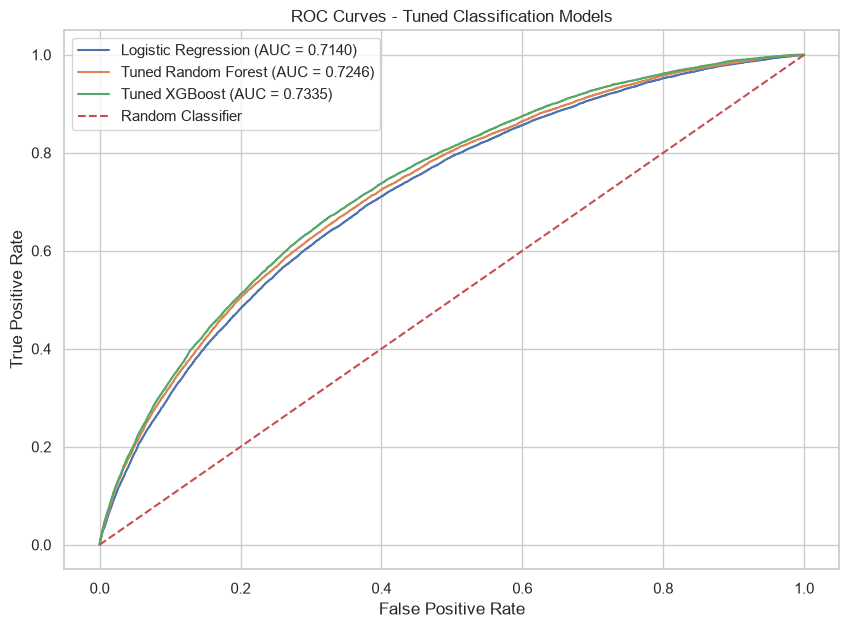

In [35]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in tuned_validation_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Tuned Classification Models")

plt.legend()
plt.grid(True)

plt.savefig(
    FIGURES_DIR / "task4_tuned_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
best_tuned_model_name = (
    tuned_validation_df.iloc[0]["Model"]
)

best_tuned_classifier = tuned_classifiers[
    best_tuned_model_name
]

print("Best tuned classifier:", best_tuned_model_name)

Best tuned classifier: Tuned XGBoost


In [37]:
best_tuned_probabilities = tuned_validation_probabilities[
    best_tuned_model_name
]

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val,
        best_tuned_probabilities
    )
)

eligible_indices = np.where(
    recall_values[:-1] >= 0.75
)[0]

if len(eligible_indices) == 0:
    raise ValueError(
        "The selected tuned model cannot reach 75% recall."
    )

best_threshold_index = eligible_indices[
    np.argmax(precision_values[eligible_indices])
]

final_threshold = thresholds[best_threshold_index]

print("Selected tuned model:", best_tuned_model_name)
print("Final classification threshold:", final_threshold)
print(
    "Validation precision:",
    precision_values[best_threshold_index]
)
print(
    "Validation recall:",
    recall_values[best_threshold_index]
)

Selected tuned model: Tuned XGBoost
Final classification threshold: 0.43970805
Validation precision: 0.3063633973179069
Validation recall: 0.7500321874597656


In [38]:
regression_numeric_features = [
    "annual_inc",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "mort_acc",
    "pub_rec_bankruptcies"
]

regression_categorical_features = [
    "term",
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose",
    "initial_list_status",
    "application_type"
]

regression_features = (
    regression_numeric_features
    + regression_categorical_features
)

X_reg = df[regression_features].copy()
y_reg = df["loan_amnt"].copy()

X_reg_train = X_reg.loc[train_indices]
X_reg_val = X_reg.loc[val_indices]
X_reg_test = X_reg.loc[test_indices]

y_reg_train = y_reg.loc[train_indices]
y_reg_val = y_reg.loc[val_indices]
y_reg_test = y_reg.loc[test_indices]

print("Regression training shape:", X_reg_train.shape)
print("Regression validation shape:", X_reg_val.shape)
print("Regression testing shape:", X_reg_test.shape)

Regression training shape: (237618, 16)
Regression validation shape: (79206, 16)
Regression testing shape: (79206, 16)


In [39]:
regression_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

regression_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

regression_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            regression_numeric_transformer,
            regression_numeric_features
        ),
        (
            "categorical",
            regression_categorical_transformer,
            regression_categorical_features
        )
    ],
    remainder="drop"
)

print("Regression preprocessor created!")

Regression preprocessor created!


In [40]:
regression_models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessor", regression_preprocessor),
        ("regressor", LinearRegression())
    ]),

    "Ridge Regression": Pipeline(steps=[
        ("preprocessor", regression_preprocessor),
        ("regressor", Ridge(alpha=10))
    ]),

    "Lasso Regression": Pipeline(steps=[
        ("preprocessor", regression_preprocessor),
        ("regressor", Lasso(
            alpha=10,
            max_iter=10000
        ))
    ])
}

print("Regression models initialized!")

Regression models initialized!


In [41]:
for model_name, model in regression_models.items():

    print(f"\nTraining {model_name}...")

    model.fit(
        X_reg_train,
        y_reg_train
    )

    print(f"{model_name} completed!")


Training Linear Regression...
Linear Regression completed!

Training Ridge Regression...
Ridge Regression completed!

Training Lasso Regression...
Lasso Regression completed!


In [42]:
mean_baseline_value = y_reg_train.mean()

baseline_predictions = np.full(
    shape=len(y_reg_val),
    fill_value=mean_baseline_value
)

print("Training mean loan amount:", mean_baseline_value)

Training mean loan amount: 14130.55723892971


In [43]:
regression_results = []

regression_predictions = {}

# Mean baseline
regression_predictions["Mean Baseline"] = baseline_predictions

regression_results.append({
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(
        y_reg_val,
        baseline_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_reg_val,
            baseline_predictions
        )
    ),
    "R2": r2_score(
        y_reg_val,
        baseline_predictions
    )
})

# Actual regression models
for model_name, model in regression_models.items():

    predictions = model.predict(X_reg_val)

    regression_predictions[model_name] = predictions

    regression_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(
            y_reg_val,
            predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_reg_val,
                predictions
            )
        ),
        "R2": r2_score(
            y_reg_val,
            predictions
        )
    })

regression_results_df = pd.DataFrame(
    regression_results
).sort_values(
    by="RMSE"
)

display(regression_results_df.round(4))

,Model,MAE,RMSE,R2
3,Lasso Regression,5055.1906,6661.8801,0.3597
1,Linear Regression,5050.4380,6674.8539,0.3573
2,Ridge Regression,5050.4085,6675.0034,0.3572
0,Mean Baseline,6747.8530,8325.8012,-0.0000


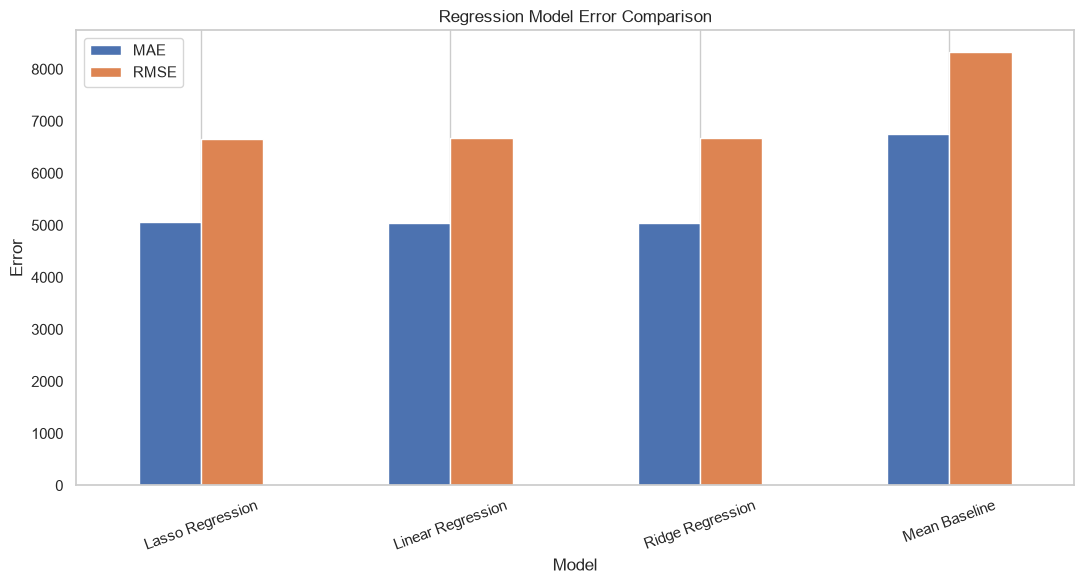

In [44]:
plot_df = regression_results_df.set_index("Model")

plot_df[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Regression Model Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=20)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task4_regression_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

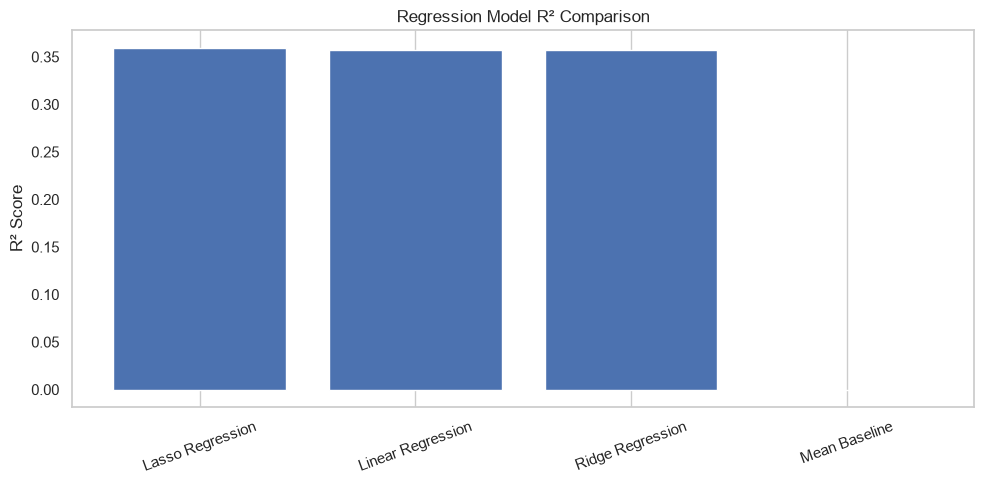

In [45]:
plt.figure(figsize=(10, 5))

plt.bar(
    regression_results_df["Model"],
    regression_results_df["R2"]
)

plt.title("Regression Model R² Comparison")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.grid(axis="y")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task4_regression_r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
best_regression_model_name = (
    regression_results_df[
        regression_results_df["Model"] != "Mean Baseline"
    ].iloc[0]["Model"]
)

best_regression_model = regression_models[
    best_regression_model_name
]

print("Best regression model:", best_regression_model_name)

Best regression model: Lasso Regression


In [47]:
# Predict test probabilities exactly once
final_test_probabilities = (
    best_tuned_classifier.predict_proba(X_test)[:, 1]
)

# Apply the threshold selected using validation data
final_test_predictions = (
    final_test_probabilities >= final_threshold
).astype(int)

final_classification_metrics = {
    "Model": best_tuned_model_name,
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(
        y_test,
        final_test_predictions
    ),
    "Precision": precision_score(
        y_test,
        final_test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        final_test_predictions,
        zero_division=0
    ),
    "F1 Score": f1_score(
        y_test,
        final_test_predictions,
        zero_division=0
    ),
    "ROC AUC": roc_auc_score(
        y_test,
        final_test_probabilities
    )
}

final_classification_df = pd.DataFrame([
    final_classification_metrics
])

print("FINAL CLASSIFICATION TEST RESULTS")
display(final_classification_df.round(4))

FINAL CLASSIFICATION TEST RESULTS


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Tuned XGBoost,0.4397,0.615,0.3043,0.7482,0.4326,0.7323


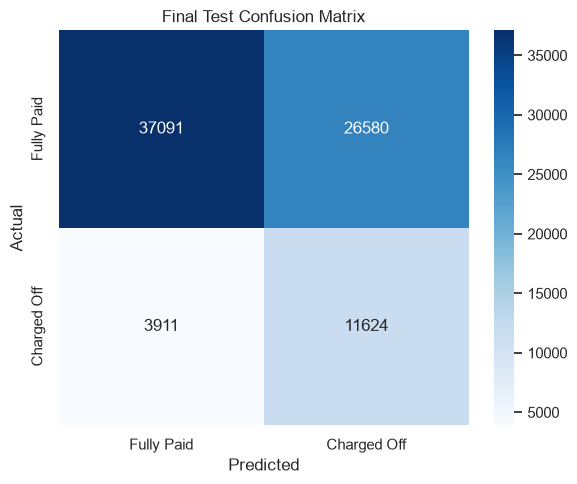

              precision    recall  f1-score   support

  Fully Paid       0.90      0.58      0.71     63671
 Charged Off       0.30      0.75      0.43     15535

    accuracy                           0.62     79206
   macro avg       0.60      0.67      0.57     79206
weighted avg       0.79      0.62      0.65     79206



In [48]:
final_cm = confusion_matrix(
    y_test,
    final_test_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fully Paid", "Charged Off"],
    yticklabels=["Fully Paid", "Charged Off"]
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task4_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["Fully Paid", "Charged Off"],
        zero_division=0
    )
)

In [49]:
# Predict test loan amounts using the selected regression model
final_regression_predictions = best_regression_model.predict(
    X_reg_test
)

final_regression_metrics = {
    "Model": best_regression_model_name,
    "MAE": mean_absolute_error(
        y_reg_test,
        final_regression_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_reg_test,
            final_regression_predictions
        )
    ),
    "R2": r2_score(
        y_reg_test,
        final_regression_predictions
    )
}

final_regression_df = pd.DataFrame([
    final_regression_metrics
])

print("FINAL REGRESSION TEST RESULTS")
display(final_regression_df.round(4))

FINAL REGRESSION TEST RESULTS


,Model,MAE,RMSE,R2
0,Lasso Regression,5070.0273,6582.9551,0.3795


In [50]:
final_baseline_predictions = np.full(
    shape=len(y_reg_test),
    fill_value=mean_baseline_value
)

final_baseline_metrics = {
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(
        y_reg_test,
        final_baseline_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_reg_test,
            final_baseline_predictions
        )
    ),
    "R2": r2_score(
        y_reg_test,
        final_baseline_predictions
    )
}

final_regression_comparison = pd.DataFrame([
    final_baseline_metrics,
    final_regression_metrics
])

display(final_regression_comparison.round(4))

,Model,MAE,RMSE,R2
0,Mean Baseline,6787.9604,8357.1776,-0.0000
1,Lasso Regression,5070.0273,6582.9551,0.3795


In [51]:
joblib.dump(
    best_tuned_classifier,
    MODELS_DIR / "task4_best_classifier.joblib"
)

joblib.dump(
    best_regression_model,
    MODELS_DIR / "task4_best_regressor.joblib"
)

task4_threshold = {
    "model_name": best_tuned_model_name,
    "threshold": float(final_threshold),
    "validation_recall_target": 0.75
}

joblib.dump(
    task4_threshold,
    MODELS_DIR / "task4_classification_threshold.joblib"
)

print("Final models and threshold saved successfully!")

Final models and threshold saved successfully!


In [52]:
classification_results_df.to_csv(
    PROJECT_ROOT / "reports" / "task4_initial_classification_results.csv",
    index=False
)

tuned_validation_df.to_csv(
    PROJECT_ROOT / "reports" / "task4_tuned_classification_results.csv",
    index=False
)

rf_results_df.to_csv(
    PROJECT_ROOT / "reports" / "task4_random_forest_search_results.csv",
    index=False
)

xgb_results_df.to_csv(
    PROJECT_ROOT / "reports" / "task4_xgboost_search_results.csv",
    index=False
)

regression_results_df.to_csv(
    PROJECT_ROOT / "reports" / "task4_regression_results.csv",
    index=False
)

final_classification_df.to_csv(
    PROJECT_ROOT / "reports" / "task4_final_classification_test.csv",
    index=False
)

final_regression_comparison.to_csv(
    PROJECT_ROOT / "reports" / "task4_final_regression_test.csv",
    index=False
)

print("All Task 4 evaluation reports saved!")

All Task 4 evaluation reports saved!


In [53]:
print("=" * 65)
print("TASK 4 - FINAL PROJECT SUMMARY")
print("=" * 65)

print("\nCLASSIFICATION")
print("Selected model:", best_tuned_model_name)
print("Selected threshold:", round(final_threshold, 4))
print(
    "Test accuracy:",
    round(final_classification_metrics["Accuracy"], 4)
)
print(
    "Test precision:",
    round(final_classification_metrics["Precision"], 4)
)
print(
    "Test recall:",
    round(final_classification_metrics["Recall"], 4)
)
print(
    "Test F1:",
    round(final_classification_metrics["F1 Score"], 4)
)
print(
    "Test ROC-AUC:",
    round(final_classification_metrics["ROC AUC"], 4)
)

print("\nREGRESSION")
print("Selected model:", best_regression_model_name)
print(
    "Test MAE:",
    round(final_regression_metrics["MAE"], 2)
)
print(
    "Test RMSE:",
    round(final_regression_metrics["RMSE"], 2)
)
print(
    "Test R2:",
    round(final_regression_metrics["R2"], 4)
)

print("\n" + "=" * 65)
print("TASK 4 COMPLETED")
print("=" * 65)

TASK 4 - FINAL PROJECT SUMMARY

CLASSIFICATION
Selected model: Tuned XGBoost
Selected threshold: 0.4397
Test accuracy: 0.615
Test precision: 0.3043
Test recall: 0.7482
Test F1: 0.4326
Test ROC-AUC: 0.7323

REGRESSION
Selected model: Lasso Regression
Test MAE: 5070.03
Test RMSE: 6582.96
Test R2: 0.3795

TASK 4 COMPLETED
